# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [29]:
!pip install nltk pandas matplotlib

In [30]:
ROLL_NO = 1024170140          # <-- your full roll number
NAME = "Eaimanjot Singh"            # <-- your name

import nltk
import re
import string
import math
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [31]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [32]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [33]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170140   Name: Eaimanjot Singh   Fingerprint: B18449F4   Tickets: 12

Ticket_ID                                                                           Ticket_Text
      T01           I cannot access the laptop after resetting my password. Can you check this?
      T02                                                 Nothing works and nobody has replied.
      T03                                                           My roll no. is 1023-03-021.
      T04 Server has stopped syncing after resetting my password. It works on another computer.
      T05            I cannot access the projector after resetting my password. This is urgent.
      T06                                                 I tried again... still no response!!!
      T07                                                  Python 3.12 was installed yesterday.
      T08                                  The projector is running slowly. Can you check this?
      T09      I am unable to use the projector w

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [34]:
results = []

total_sentences = 0
total_tokens = 0
total_punctuation = 0
total_stopwords = 0
total_final = 0

for i in range(len(df)):
    ticket_id = df.iloc[i]["Ticket_ID"]
    ticket_text = df.iloc[i]["Ticket_Text"]

    result = process_ticket(ticket_text)

    sentence_count = len(result["sentences"])
    token_count = len(result["tokens"])
    punctuation_count = len(result["punct"])
    stopword_count = len(result["stops"])
    unique_count = len(set(result["tokens"]))
    final_count = len(result["final"])

    results.append({
        "Ticket_ID": ticket_id,
        "Sentences": sentence_count,
        "Tokens": token_count,
        "Punctuation": punctuation_count,
        "Stopwords": stopword_count,
        "Unique Tokens": unique_count,
        "Final Tokens": final_count
    })

    total_sentences += sentence_count
    total_tokens += token_count
    total_punctuation += punctuation_count
    total_stopwords += stopword_count
    total_final += final_count

results.append({
    "Ticket_ID": "TOTAL",
    "Sentences": total_sentences,
    "Tokens": total_tokens,
    "Punctuation": total_punctuation,
    "Stopwords": total_stopwords,
    "Unique Tokens": "-",
    "Final Tokens": total_final
})

q1_table = pd.DataFrame(results)
q1_table

,Ticket_ID,Sentences,Tokens,Punctuation,Stopwords,Unique Tokens,Final Tokens
0,T01,2,16,2,9,15,5
1,T02,1,7,1,2,7,4
2,T03,2,7,2,3,6,2
3,T04,2,15,2,5,14,8
4,T05,2,15,2,8,14,5
5,T06,2,10,4,3,8,3
6,T07,1,6,1,1,6,4
7,T08,2,11,2,5,11,4
8,T09,2,17,2,8,15,7
9,T10,2,12,2,4,11,6


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* Some final tokens may not look like complete words, such as `n't`, `'s` or `ca`. They can come from contractions such as *isn't*, *user's* and *can't*. The tokenizer separates parts of contractions, and the preprocessing function removes punctuation and stopwords but does not join those parts back together.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [35]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

raw_tickets = list(df["Ticket_Text"])

# Use the supplied test lines from the starter notebook
print("TEST_LINES:")
for line in TEST_LINES:
    print(line)

def show_extractions(text):
    long_words = re.findall(r"\b[A-Za-z]{6,}\b", text)
    numbers = re.findall(r"\b\d+(?:\.\d+)+|\b\d+(?:,\d{3})*(?:\.\d+)?", text)
    capitalized = re.findall(r"\b[A-Z][a-zA-Z]*\b", text)
    vowel_words = re.findall(r"\b[aeiouAEIOU][a-zA-Z]*\b", text)

    print("Words longer than 5 letters:", long_words)
    print("Numbers:", numbers)
    print("Capitalized words:", capitalized)
    print("Words beginning with a vowel:", vowel_words)

for i in range(len(raw_tickets)):
    print("\nTicket", i + 1, ":", raw_tickets[i])
    show_extractions(raw_tickets[i])

print("\nEXTRACTIONS FROM TEST_LINES")
for line in TEST_LINES:
    print("\nText:", line)
    show_extractions(line)

TEST_LINES:
Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.

Ticket 1 : I cannot access the laptop after resetting my password. Can you check this?
Words longer than 5 letters: ['cannot', 'access', 'laptop', 'resetting', 'password']
Numbers: []
Capitalized words: ['I', 'Can']
Words beginning with a vowel: ['I', 'access', 'after']

Ticket 2 : Nothing works and nobody has replied.
Words longer than 5 letters: ['Nothing', 'nobody', 'replied']
Numbers: []
Capitalized words: ['Nothing']
Words beginning with a vowel: ['and']

Ticket 3 : My roll no. is 1023-03-021.
Words longer than 5 letters: []
Numbers: ['1023', '03', '021']
Capitalized words: ['My']
Words beginning with a vowel: ['is']

Ticket 4 : Server has stopped syncing after resetting my password. It works o

In [36]:
email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
url_pattern = r"https?://\S+|www\.\S+"
phone_pattern = r"(?<!\w)(?:\+?\d{1,3}[- ]?)?\d{3,5}[- ]\d{3,5}[- ]\d{3,5}(?!\w)"

def hide_contact_details(text):
    text = re.sub(email_pattern, "<EMAIL>", text)
    text = re.sub(url_pattern, "<URL>", text)
    text = re.sub(phone_pattern, "<PHONE>", text)
    return text

print("REPLACEMENT ON TEST_LINES")
for line in TEST_LINES:
    print("\nOriginal:", line)
    print("Changed :", hide_contact_details(line))

print("\nREPLACEMENT ON TICKETS")
for ticket in raw_tickets:
    print(hide_contact_details(ticket))

REPLACEMENT ON TEST_LINES

Original: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Changed : Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>

Original: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Changed : Call +91 98765 43210, +91-98765-43210 or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.

Original: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
Changed : The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.

REPLACEMENT ON TICKETS
I cannot access the laptop after resetting my password. Can you check this?
Nothing works and nobody has replied.
My roll no. is 1023-03-021.
Server has stopped syncing after resetting my password. It works on another computer.
I cannot access the projector after resetting my password. This is urgent.
I tried again... still no response!!!
Python 3.12 was installed yesterday.
The projector is runn

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* A capitalized word may be capitalized only because it begins a sentence. For example, `The`, `I` and `Call` can appear at the beginning of a sentence. Other capitalized words, such as `Python`, `MATLAB` and `VPN`, may be names or abbreviations. A regular expression alone cannot always tell the reason for capitalization.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [37]:
from nltk.tokenize import RegexpTokenizer, word_tokenize

pattern = (
    r"https?://\S+|www\.\S+|"                         # URLs
    r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|" # email
    r"\+?\d{1,3}[- ]\d{3,5}[- ]\d{3,5}[- ]\d{3,5}|"   # phone
    r"\d+(?:\.\d+){2,}|"                              # versions e.g. 2.0.1
    r"\d+\.\d+|"                                      # decimals e.g. 95.5
    r"[A-Za-z]+(?:'[A-Za-z]+)+|"                      # contractions
    r"[A-Za-z]+(?:-[A-Za-z]+)+|"                      # hyphenated words
    r"[A-Za-z]+|"                                     # normal words
    r"\d+|"                                           # integers
    r"[^\w\s]"                                        # punctuation
)

my_tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return my_tokenizer.tokenize(text)

print("CUSTOM TOKENIZER ON TEST_LINES")
for line in TEST_LINES:
    print("\nText:", line)
    print("My tokens:", my_tokenize(line))
    print("NLTK tokens:", word_tokenize(line))

print("\nCUSTOM TOKENIZER ON GENERATED TICKETS")
for i in range(len(raw_tickets)):
    print("\nTicket:", df.iloc[i]["Ticket_ID"])
    print("My tokens:", my_tokenize(raw_tickets[i]))
    print("NLTK tokens:", word_tokenize(raw_tickets[i]))

CUSTOM TOKENIZER ON TEST_LINES

Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
My tokens: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
NLTK tokens: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
My tokens: ['Call', '+', '91', '98765', '43210', ',', '+', '91', '-', '98765', '-', '43210', 'or', '0175', '-', '239', '-', '3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
NLTK tokens: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Text: The sta

In [38]:
# Count how many tickets produce different token lists
different_tickets = 0

for ticket in raw_tickets:
    my_words = my_tokenize(ticket)
    nltk_words = word_tokenize(ticket)

    if my_words != nltk_words:
        different_tickets += 1

print("Tickets tokenized differently:", different_tickets)
print("Total tickets:", len(raw_tickets))

Tickets tokenized differently: 4
Total tickets: 12


**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* 1. A contraction such as `isn't` is kept as one token by the custom tokenizer, while `word_tokenize()` commonly separates it into `is` and `n't`.
2. A hyphenated word such as `state-of-the-art` is kept as one token by the custom tokenizer, while `word_tokenize()` separates it at hyphens.
3. A decimal such as `95.5` is kept as one token by the custom tokenizer, while `word_tokenize()` may separate the number and decimal point.

The custom tokenizer is designed for the formats required in this assignment. `word_tokenize()` is a general-purpose tokenizer.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [39]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag

# Collect unique final tokens from all tickets
all_final_tokens = []

for ticket in raw_tickets:
    ticket_result = process_ticket(ticket)
    all_final_tokens.extend(ticket_result["final"])

unique_final_tokens = sorted(set(all_final_tokens))

porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp_stemmer = RegexpStemmer("ing$")
lemmatizer = WordNetLemmatizer()

# POS tag all words
tagged_words = pos_tag(unique_final_tokens)

def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return "a"
    elif tag.startswith("V"):
        return "v"
    elif tag.startswith("N"):
        return "n"
    elif tag.startswith("R"):
        return "r"
    else:
        return "n"

different_results = []

for word, tag in tagged_words:
    porter_word = porter.stem(word)
    lancaster_word = lancaster.stem(word)
    regexp_word = regexp_stemmer.stem(word)
    lemma_word = lemmatizer.lemmatize(word, get_wordnet_pos(tag))

    # Show only words where at least two methods give different outputs
    if len(set([porter_word, lancaster_word, regexp_word, lemma_word])) > 1:
        different_results.append({
            "Original Word": word,
            "Porter": porter_word,
            "Lancaster": lancaster_word,
            "Regexp": regexp_word,
            "POS Lemma": lemma_word
        })

stem_table = pd.DataFrame(different_results)
stem_table

,Original Word,Porter,Lancaster,Regexp,POS Lemma
0,another,anoth,anoth,another,another
1,campus,campu,camp,campus,campus
2,computer,comput,comput,computer,computer
3,connected,connect,connect,connected,connect
4,installed,instal,instal,installed,installed
5,keeps,keep,keep,keeps,keep
6,latest,latest,latest,latest,late
7,lms,lm,lms,lms,lm
8,nobody,nobodi,nobody,nobody,nobody
9,nothing,noth,noth,noth,nothing


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* I selected `ing$` after observing ticket words such as `syncing` and `responding`. Removing `ing` gives a simple shortened form. This is a basic rule and does not always produce a proper dictionary word.

**Note:** POS-aware lemmatization uses the part-of-speech tag to choose whether a word is a noun, verb, adjective or adverb before finding its base form.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

In [40]:
# Build the four token collections
S1 = []
S2 = []
S3 = []

for ticket in raw_tickets:
    result = process_ticket(ticket)
    S1.extend(result["tokens"])
    S2.extend([word for word in result["tokens"] if word not in result["punct"]])
    S3.extend(result["final"])

# Porter stemming for S4
S4 = []

for word in S3:
    S4.append(porter.stem(word))

def corpus_values(words):
    total = len(words)
    unique = len(set(words))

    if total == 0:
        ttr = 0
    else:
        ttr = unique / total

    return total, unique, round(ttr, 3)

statistics = []

for name, words in [("S1 - All tokens", S1),
                    ("S2 - No punctuation", S2),
                    ("S3 - Final tokens", S3),
                    ("S4 - Porter stemmed", S4)]:
    total, unique, ttr = corpus_values(words)

    statistics.append({
        "Corpus": name,
        "Total Tokens": total,
        "Unique Tokens": unique,
        "TTR": ttr
    })

pd.DataFrame(statistics)

,Corpus,Total Tokens,Unique Tokens,TTR
0,S1 - All tokens,139,63,0.453
1,S2 - No punctuation,115,59,0.513
2,S3 - Final tokens,59,40,0.678
3,S4 - Porter stemmed,59,40,0.678


In [41]:
# Top 10 words of S1 and S3
print("Top 10 words in S1:")
print(Counter(S1).most_common(10))

print("\nTop 10 words in S3:")
print(Counter(S3).most_common(10))

Top 10 words in S1:
[('.', 17), ('the', 7), ('can', 5), ('this', 5), ('is', 5), ('i', 4), ('after', 4), ('my', 4), ('resetting', 3), ('password', 3)]

Top 10 words in S3:
[('resetting', 3), ('password', 3), ('check', 3), ('works', 3), ('projector', 3), ('access', 2), ('stopped', 2), ('syncing', 2), ('another', 2), ('computer', 2)]


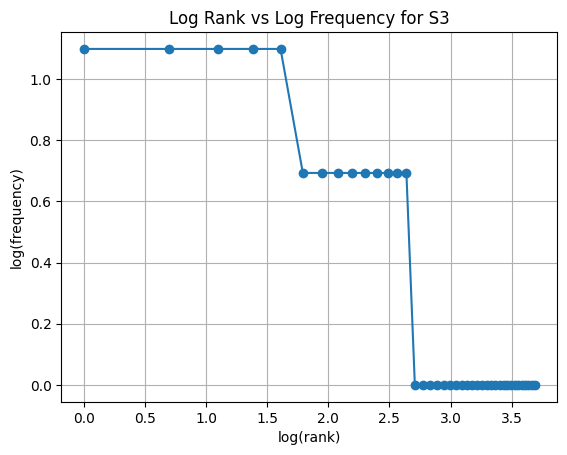

In [42]:
# Plot log(rank) vs log(frequency) for S3
frequency_list = Counter(S3).most_common()

ranks = []
frequencies = []

for rank, item in enumerate(frequency_list, start=1):
    word = item[0]
    count = item[1]

    ranks.append(math.log(rank))
    frequencies.append(math.log(count))

plt.plot(ranks, frequencies, marker="o")
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Log Rank vs Log Frequency for S3")
plt.grid(True)
plt.show()

In [43]:
# Find top 5 bigrams without using an extra library
def get_bigrams(words):
    pairs = []

    for i in range(len(words) - 1):
        pairs.append((words[i], words[i + 1]))

    return pairs

print("Top 5 bigrams in S1:")
print(Counter(get_bigrams(S1)).most_common(5))

print("\nTop 5 bigrams in S3:")
print(Counter(get_bigrams(S3)).most_common(5))

Top 5 bigrams in S1:
[(('after', 'resetting'), 3), (('resetting', 'my'), 3), (('my', 'password'), 3), (('password', '.'), 3), (('.', 'can'), 3)]

Top 5 bigrams in S3:
[(('resetting', 'password'), 3), (('stopped', 'syncing'), 2), (('works', 'another'), 2), (('another', 'computer'), 2), (('running', 'slowly'), 2)]


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR is the number of unique tokens divided by the total number of tokens. Removing punctuation and stopwords changes the words included in the corpus. Porter stemming also converts related words to similar root forms, which can reduce the number of unique tokens. Therefore, TTR can change from S1 to S4.